# Tutorial: static, buckling, frequency and non-linear analyses of a von Mises truss

This tutorial runs one of the analytic problems of the unit tests of
`structsolve`, the function `von_mises_truss` of
`tests/analytic_problems.py`, copied below, through the analyses of
`structsolve`: linear static, linear buckling, frequency, and non-linear
static with the Newton-Raphson and the arc-length methods.

The shallow von Mises truss of height 1 is loaded through a linear spring of
stiffness $k_s$. The degree of freedom 0 is the apex deflection $w = c_0$,
the degree of freedom 1 the displacement $c_1$ of the loaded point, and the
internal force vector is

$$
\{F_{int}\} = \begin{Bmatrix} w^3 - 3 w^2 + 2 w + k_s (c_0 - c_1) \\ k_s (c_1 - c_0) \end{Bmatrix}
$$

with the tangent stiffness matrix $[K_C] + [K_G]$, where $[K_C]$ is the
linear stiffness matrix and $[K_G]$ contains the derivative $3 w^2 - 6 w$ of
the non-linear terms. The truss reaches a limit point at
$w = 1 - 1/\sqrt{3}$, under the limit load $F_{lim} = 2/(3\sqrt{3})$. The
reference load is `frac` times the limit load.

The model is given to `structsolve` by the four callables of `Analysis`, which return the external and the internal force vectors and the two parts of the tangent stiffness matrix:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

from structsolve import Analysis, freq, lb

frac = 1.5
ks = 10.
F_lim = 2/(3*np.sqrt(3))
w_lim = 1 - 1/np.sqrt(3)
fext = np.array([0., frac*F_lim])
kC = np.array([[2. + ks, -ks], [-ks, ks]])


def calc_fext(inc=1., silent=True):
    return inc*fext


def calc_fint(c, silent=True):
    w = c[0]
    return np.array([w**3 - 3*w**2 + 2*w + ks*(c[0] - c[1]),
                     ks*(c[1] - c[0])])


def calc_kC(c=None, NLgeom=False, silent=True):
    return csr_matrix(kC)


def calc_kG(c=None, NLgeom=False, silent=True):
    w = c[0]
    return csr_matrix(np.array([[3*w**2 - 6*w, 0.], [0., 0.]]))


def analysis(**kwargs):
    an = Analysis(calc_fext=calc_fext, calc_fint=calc_fint, calc_kC=calc_kC,
                  calc_kG=calc_kG)
    for name, value in kwargs.items():
        setattr(an, name, value)
    return an


print('reference load:', fext)

reference load: [0.         0.57735027]


## Linear static analysis

`Analysis.static(NLgeom=False)` solves $[K_0]\{c\} = \{F_{ext}\}$ with the callables `calc_kC()` and `calc_fext()`:

In [2]:
an = analysis()
increments, cs = an.static(NLgeom=False, silent=True)
c_lin = cs[0]
print('linear solution:', c_lin)

linear solution: [0.28867513 0.34641016]


## Linear buckling analysis

The geometric stiffness matrix of the linear solution gives the eigenvalue problem $([K_0] + \lambda [K_G(c_{lin})])\{u\} = \{0\}$. With only two degrees of freedom the dense solver is used explicitly, `sparse_solver=False`, which returns all the load multipliers:

In [3]:
K0 = calc_kC()
KG = calc_kG(c_lin)
eigvals, eigvecs = lb(K0, KG, silent=True, sparse_solver=False)
print('load multipliers:', eigvals)
print('linear buckling estimate of the limit load factor:', eigvals[0])
print('limit load factor:', 1/frac)

load multipliers: [ 1.3494814e+00 -7.2057594e+16]
linear buckling estimate of the limit load factor: 1.3494814008979579
limit load factor: 0.6666666666666666


The linear buckling analysis assumes a linear pre-buckling path, with $[K_G]$ proportional to the load. The path of the truss is strongly non-linear before its limit point, and the estimate is here about twice the limit load factor. The non-linear analyses below trace the actual path. The row of the loaded point is null in $[K_G]$, and the second load multiplier, of the order of $10^{16}$, is infinite up to the round-off.

## Non-linear static analyses

The Newton-Raphson method controls the load factor, and the arc-length methods of Riks and Crisfield control the arc length, such that the load factor may decrease after the limit point:

In [4]:
results = {}
for method in ['NR', 'arc_length_riks', 'arc_length_crisfield']:
    an = analysis(NL_method=method, initialInc=0.05)
    an.static(NLgeom=True, silent=True)
    results[method] = (np.array(an.increments), np.array(an.cs))
    print('%-21s %3d increments, last load factor %.3f'
          % (method, len(an.increments), an.increments[-1]))

NR                     12 increments, last load factor 1.000
arc_length_riks        18 increments, last load factor 1.000
arc_length_crisfield   14 increments, last load factor 1.000


All the analyses finish at the load factor 1.0. The load-displacement curves of `an.increments` and `an.cs`, with the load $\lambda \, \mathrm{frac} \, F_{lim}$ normalized by the limit load, against the exact equilibrium path $F = w^3 - 3 w^2 + 2 w$ of the apex:

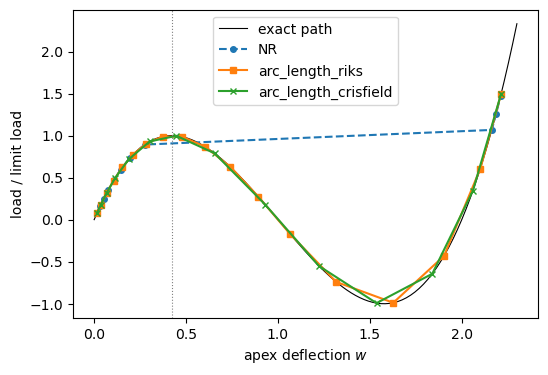

In [5]:
w = np.linspace(0, 2.3, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(w, (w**3 - 3*w**2 + 2*w)/F_lim, 'k-', lw=0.8, label='exact path')
styles = {'NR': 'o--', 'arc_length_riks': 's-', 'arc_length_crisfield': 'x-'}
for method, (inc, cs) in results.items():
    ax.plot(cs[:, 0], inc*frac, styles[method], ms=4, label=method)
ax.axvline(w_lim, color='gray', ls=':', lw=0.8)
ax.set_xlabel('apex deflection $w$')
ax.set_ylabel('load / limit load')
ax.legend()
plt.show()

The Newton-Raphson increments follow the path below the limit load and then jump to the inverted configuration, where the load is again larger than the limit load: the analysis converges, but the unstable part of the path is skipped. The arc-length methods pass the limit point, the load factor decreasing and becoming negative during the snap-through, and reach the same final state:

In [6]:
for method, (inc, cs) in results.items():
    print('%-21s largest jump of w: %.3f, final c: %s'
          % (method, np.diff(cs[:, 0]).max(), cs[-1]))

NR                    largest jump of w: 1.889, final c: [2.21463146 2.27236649]
arc_length_riks       largest jump of w: 0.311, final c: [2.21463146 2.27236649]
arc_length_crisfield  largest jump of w: 0.313, final c: [2.21463146 2.27236649]


## Frequency analysis along the path

With unit masses at both degrees of freedom, $[M] = [I]$, the frequency analysis of the tangent stiffness matrix $[K_T(c)] = [K_C] + [K_G(c)]$ at each converged state of the Riks analysis gives $\omega^2 = -\lambda^2$. The lowest $\omega^2$ vanishes where $[K_T]$ is singular, at the limit points $w = 1 \mp 1/\sqrt{3}$, and is negative between them, where the equilibrium is unstable:

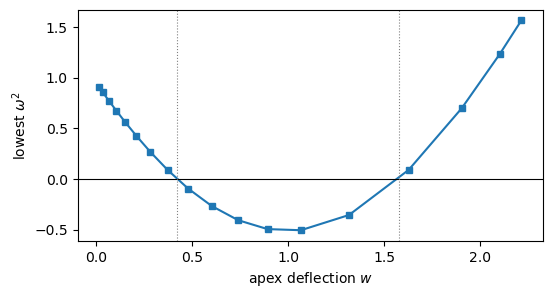

In [7]:
inc, cs = results['arc_length_riks']
M = csr_matrix(np.eye(2))
omega2 = []
for c in cs:
    KT = calc_kC(c, NLgeom=True) + calc_kG(c, NLgeom=True)
    lambda2, _ = freq(KT, M, silent=True, sparse_solver=False,
                      symmetric=True, sort=False)
    omega2.append(-lambda2.max())

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(cs[:, 0], omega2, 's-', ms=4)
ax.axhline(0, color='k', lw=0.8)
for wl in (1 - 1/np.sqrt(3), 1 + 1/np.sqrt(3)):
    ax.axvline(wl, color='gray', ls=':', lw=0.8)
ax.set_xlabel('apex deflection $w$')
ax.set_ylabel(r'lowest $\omega^2$')
plt.show()